# Phase 10 Pre-Registration: Time Series Analysis

Date: 2026-10-17

## Hypotheses

H9 (Self-excitation): The DeFi liquidation event stream exhibits 
    self-excitation (Hawkes process), rejecting the null hypothesis 
    of independent Poisson arrivals.

H10 (Granger causality): Market-wide activity (borrow volume, deposit 
     outflows) Granger-causes liquidation rate at lag ≤ 7 days.

H11 (Non-stationarity): Daily liquidation count series exhibits a unit 
     root (non-stationary), consistent with regime-shifting dynamics.

## Decision rules

- H9 POSITIVE: Hawkes branching ratio η > 0.1 AND likelihood-ratio 
  test p < 0.001 vs Poisson null
- H10 POSITIVE: at least one market variable Granger-causes liquidation 
  rate at p < 0.05 (BH-corrected) at some lag ∈ {1..7}
- H11 POSITIVE: ADF test fails to reject unit root (p > 0.05) at 
  daily resolution

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.optimize import minimize
from scipy.stats import chi2

ROOT = Path("data")
RAW_ROOT = ROOT / "raw"
TS_DIR = ROOT / "eval" / "ts"
TS_DIR.mkdir(parents=True, exist_ok=True)

with open(ROOT / "processed" / "task_registry.json") as f:
    TASKS = json.load(f)

TASK = "Borrow_Liquidated"
task = next(t for t in TASKS if t["task_id"] == TASK)

HOLDOUT_START = pd.Timestamp("2024-04-01").timestamp()

df = pd.read_csv(RAW_ROOT / task["train_path"].replace("\\", "/"),
                 usecols=["timestamp", "status", "amountUSD"])
df = df[df["timestamp"] < HOLDOUT_START].reset_index(drop=True)
df["dt"] = pd.to_datetime(df["timestamp"], unit="s")
print(f"total events: {len(df)}, liquidations: {df['status'].sum()}")
print(f"date range: {df['dt'].min()} to {df['dt'].max()}")

total events: 786960, liquidations: 22349.0
date range: 2022-03-14 12:40:09 to 2024-03-31 23:59:18


In [2]:
# Daily liquidation count
liq = df[df["status"] == 1].copy()
liq["date"] = liq["dt"].dt.date
daily_liq = liq.groupby("date").size().rename("liquidations")

# Daily all-event activity (for Granger)
df["date"] = df["dt"].dt.date
daily_vol = df.groupby("date").size().rename("total_events")
daily_amt = df.groupby("date")["amountUSD"].sum().rename("total_amountUSD")

# Align
all_dates = pd.date_range(daily_liq.index.min(), daily_liq.index.max(), freq='D').date
daily = pd.DataFrame(index=all_dates)
daily["liquidations"] = daily_liq.reindex(all_dates, fill_value=0)
daily["total_events"] = daily_vol.reindex(all_dates, fill_value=0)
daily["total_amountUSD"] = daily_amt.reindex(all_dates, fill_value=0)
daily["log_amountUSD"] = np.log1p(daily["total_amountUSD"])

print(f"series length: {len(daily)} days")
print(daily.head())
print(f"\nliquidation stats: mean={daily['liquidations'].mean():.1f}, "
      f"std={daily['liquidations'].std():.1f}, max={daily['liquidations'].max()}")

series length: 747 days
            liquidations  total_events  total_amountUSD  log_amountUSD
2022-03-16            13           156     2.525798e+05      12.439486
2022-03-17            12           422     1.396983e+06      14.149826
2022-03-18            12           265     1.125349e+06      13.933605
2022-03-19            21           278     6.905106e+05      13.445188
2022-03-20            30           242     7.989112e+05      13.591006

liquidation stats: mean=29.9, std=22.8, max=239


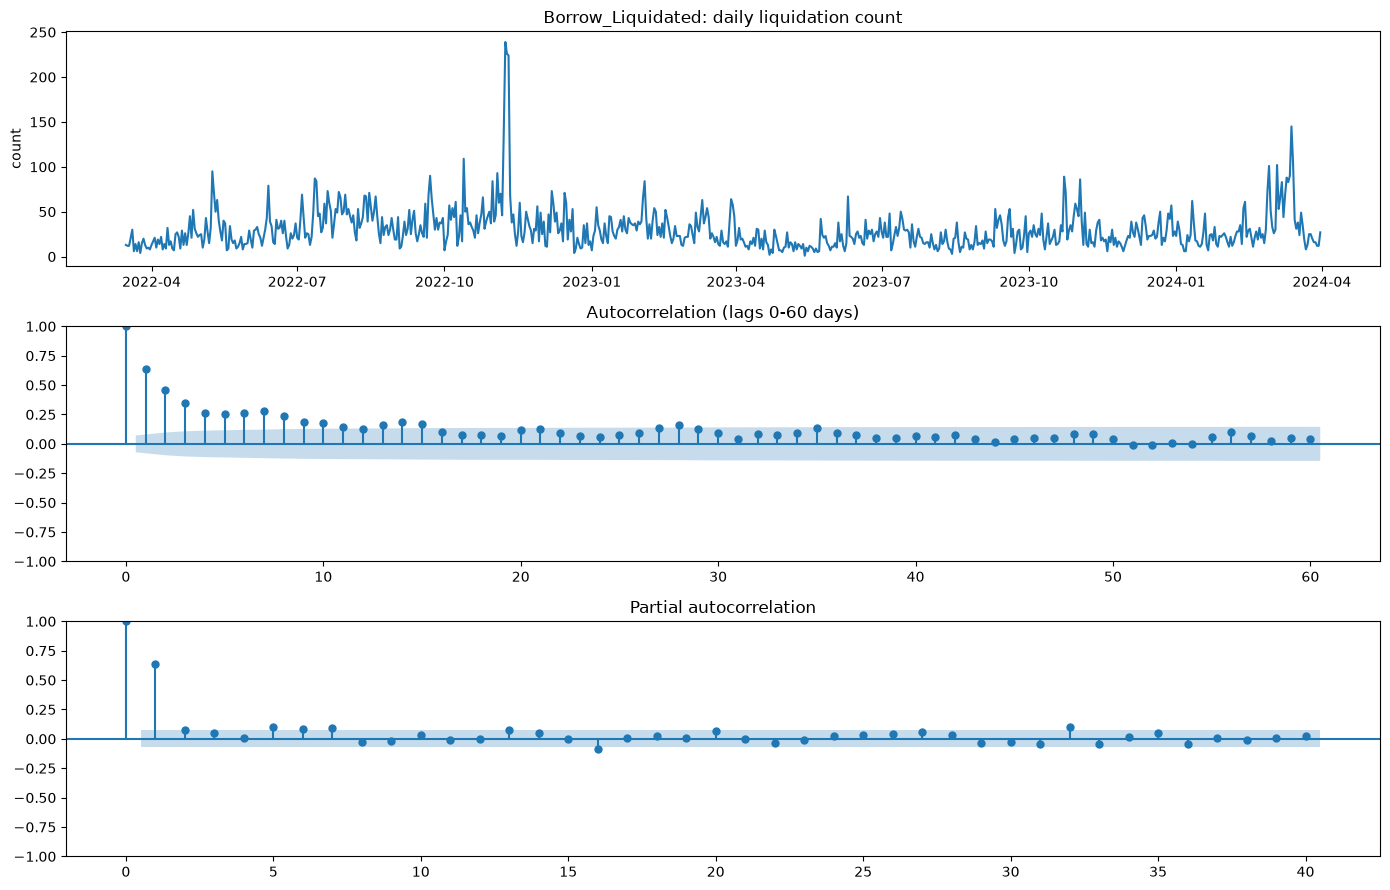


ADF test: statistic=-5.974, p=0.0000
  critical values: {'1%': np.float64(-3.4392177416762086), '5%': np.float64(-2.8654536415414684), '10%': np.float64(-2.5688540485756026)}
  verdict: stationary

KPSS test: statistic=0.415, p=0.0708
  verdict: stationary


C:\Users\Rk jha\AppData\Local\Temp\ipykernel_6740\337154176.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, _, _, adf_crit, _ = adfuller(daily["liquidations"].dropna(), autolag="AIC")
C:\Users\Rk jha\AppData\Local\Temp\ipykernel_6740\337154176.py:24: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9))

axes[0].plot(daily.index, daily["liquidations"])
axes[0].set_title(f"{TASK}: daily liquidation count")
axes[0].set_ylabel("count")

plot_acf(daily["liquidations"].values, lags=60, ax=axes[1])
axes[1].set_title("Autocorrelation (lags 0-60 days)")

plot_pacf(daily["liquidations"].values, lags=40, ax=axes[2], method='ywm')
axes[2].set_title("Partial autocorrelation")

plt.tight_layout()
plt.savefig(TS_DIR / "liq_series_acf_pacf.png", dpi=150)
plt.show()

# ADF test
adf_stat, adf_p, _, _, adf_crit, _ = adfuller(daily["liquidations"].dropna(), autolag="AIC")
print(f"\nADF test: statistic={adf_stat:.3f}, p={adf_p:.4f}")
print(f"  critical values: {adf_crit}")
print(f"  verdict: {'NON-stationary (unit root)' if adf_p > 0.05 else 'stationary'}")

# KPSS test (null is stationary)
kpss_stat, kpss_p, _, kpss_crit = kpss(daily["liquidations"].dropna(), regression='c', nlags='auto')
print(f"\nKPSS test: statistic={kpss_stat:.3f}, p={kpss_p:.4f}")
print(f"  verdict: {'NON-stationary (reject H0)' if kpss_p < 0.05 else 'stationary'}")

In [4]:
# Extract liquidation event times in seconds from epoch (sorted)
event_times = np.sort(liq["timestamp"].values)
T = event_times.max() - event_times.min()
N = len(event_times)
print(f"liquidation events: {N}, time span: {T/86400:.0f} days")

# Poisson log-likelihood: rate = N/T, ll = N*log(N/T) - N
rate_poisson = N / T
ll_poisson = N * np.log(rate_poisson) - N
print(f"\nPoisson baseline: rate={rate_poisson*86400:.3f}/day, log-lik={ll_poisson:.1f}")

# Hawkes with exponential kernel: lambda(t) = mu + alpha * sum(beta * exp(-beta * (t - t_i)))
def hawkes_neg_loglik(params, times):
    mu, alpha, beta = params
    if mu <= 0 or alpha <= 0 or beta <= 0 or alpha >= beta:
        return 1e10
    T_span = times[-1] - times[0]
    # Compute conditional intensities at each event
    # Use recursive formulation for efficiency
    R = np.zeros(len(times))
    for i in range(1, len(times)):
        R[i] = np.exp(-beta * (times[i] - times[i-1])) * (R[i-1] + 1)
    intensities = mu + alpha * R
    # Compensator
    comp_sum = np.sum(1 - np.exp(-beta * (times[-1] - times)))
    compensator = mu * T_span + (alpha / beta) * comp_sum
    ll = np.sum(np.log(intensities)) - compensator
    return -ll

# Rescale time to prevent numerical issues (use days)
t_days = (event_times - event_times[0]) / 86400.0

init = [N / T * 86400 * 0.5, 0.5, 1.0]  # mu, alpha, beta in /day units
bounds = [(1e-6, None), (1e-6, None), (1e-3, None)]
res = minimize(hawkes_neg_loglik, init, args=(t_days,),
               method='L-BFGS-B', bounds=bounds)

mu_hat, alpha_hat, beta_hat = res.x
ll_hawkes = -res.fun
branching_ratio = alpha_hat / beta_hat

print(f"\nHawkes fit:")
print(f"  mu (background rate):    {mu_hat:.4f} /day")
print(f"  alpha (jump size):       {alpha_hat:.4f}")
print(f"  beta (decay rate):       {beta_hat:.4f} /day")
print(f"  branching ratio η = α/β: {branching_ratio:.4f}")
print(f"  log-lik: {ll_hawkes:.1f}")

# LR test: Hawkes has 3 params, Poisson has 1, so 2 extra df
# For comparable likelihoods, convert Poisson to same timescale
rate_poisson_day = rate_poisson * 86400
ll_poisson_day = N * np.log(rate_poisson_day) - rate_poisson_day * (t_days[-1] - t_days[0])
LR = 2 * (ll_hawkes - ll_poisson_day)
lr_p = 1 - chi2.cdf(LR, df=2)
print(f"\nLR test (Hawkes vs Poisson):")
print(f"  LR statistic: {LR:.2f}")
print(f"  p-value: {lr_p:.3e}")

liquidation events: 22349, time span: 746 days

Poisson baseline: rate=29.951/day, log-lik=-200407.3

Hawkes fit:
  mu (background rate):    14.5520 /day
  alpha (jump size):       65.2608
  beta (decay rate):       126.9209 /day
  branching ratio η = α/β: 0.5142
  log-lik: 62871.5

LR test (Hawkes vs Poisson):
  LR statistic: 18487.04
  p-value: 0.000e+00


In [8]:
if adf_p > 0.05:
    liq_series = daily["liquidations"].diff().dropna()
    vol_series = daily["total_events"].diff().dropna()
    amt_series = daily["log_amountUSD"].diff().dropna()
    print("using first-differenced series (ADF said non-stationary)")
else:
    liq_series = daily["liquidations"]
    vol_series = daily["total_events"]
    amt_series = daily["log_amountUSD"]
    print("using level series (ADF said stationary)")

def gc_pvalues(y, x, max_lag=7):
    data = pd.concat([y, x], axis=1).dropna().values
    out = {}
    for lag in range(1, max_lag + 1):
        try:
            res = grangercausalitytests(data, maxlag=lag)
            out[lag] = res[lag][0]['ssr_ftest'][1]
        except Exception as ex:
            print(f"  lag {lag} failed: {ex}")
            out[lag] = np.nan
    return out

print("\nGranger: does total_events Granger-cause liquidations?")
gc_vol = gc_pvalues(liq_series, vol_series)
print("\nGranger: does log_amountUSD Granger-cause liquidations?")
gc_amt = gc_pvalues(liq_series, amt_series)

gc_df = pd.DataFrame({"lag": range(1, 8),
                      "p_total_events→liq": [gc_vol[l] for l in range(1, 8)],
                      "p_log_amountUSD→liq": [gc_amt[l] for l in range(1, 8)]})
print()
print(gc_df.round(4).to_string(index=False))

from statsmodels.stats.multitest import multipletests
all_p = [p for p in list(gc_vol.values()) + list(gc_amt.values()) if not np.isnan(p)]
if len(all_p) > 0:
    reject, p_corr, _, _ = multipletests(all_p, alpha=0.05, method='fdr_bh')
    print(f"\nany BH-corrected Granger p < 0.05: {reject.any()}")
    print(f"min uncorrected p: {min(all_p):.4f}")
else:
    reject = np.array([False])
    print("\nall tests failed, no p-values")

gc_df.to_csv(TS_DIR / "granger_tests.csv", index=False)

using level series (ADF said stationary)

Granger: does total_events Granger-cause liquidations?

Granger: does log_amountUSD Granger-cause liquidations?

 lag  p_total_events→liq  p_log_amountUSD→liq
   1              0.1058               0.1575
   2              0.1967               0.4547
   3              0.1146               0.4518
   4              0.0973               0.6046
   5              0.0001               0.7731
   6              0.0001               0.8362
   7              0.0000               0.8337

any BH-corrected Granger p < 0.05: True
min uncorrected p: 0.0000


In [9]:

print( "TIME SERIES VERDICT")


h9_pass = branching_ratio > 0.1 and lr_p < 0.001
h10_pass = reject.any()
h11_pass = adf_p > 0.05

print(f"\nH9 (self-excitation): branching ratio={branching_ratio:.3f}, LR p={lr_p:.3e}")
print(f"  {'POSITIVE' if h9_pass else 'NULL'}")

print(f"\nH10 (Granger causality): any BH-corrected p<0.05: {reject.any()}")
print(f"  min p (uncorrected): {min(all_p):.4f}")
print(f"  {'POSITIVE' if h10_pass else 'NULL'}")

print(f"\nH11 (non-stationarity): ADF p={adf_p:.4f}")
print(f"  {'POSITIVE' if h11_pass else 'NULL'}")

print(f"\noverall:")
if h9_pass and h10_pass:
    print("  POSITIVE: liquidations self-excite AND are predicted by market activity")
elif h9_pass:
    print("  PARTIAL POSITIVE: liquidations self-excite (Hawkes dynamics)")
elif h10_pass:
    print("  PARTIAL POSITIVE: liquidations are predicted by market activity")
else:
    print("  NULL: liquidation stream shows no strong temporal structure")

TIME SERIES VERDICT

H9 (self-excitation): branching ratio=0.514, LR p=0.000e+00
  POSITIVE

H10 (Granger causality): any BH-corrected p<0.05: True
  min p (uncorrected): 0.0000
  POSITIVE

H11 (non-stationarity): ADF p=0.0000
  NULL

overall:
  POSITIVE: liquidations self-excite AND are predicted by market activity


In [7]:
print("Granger input diagnostic:")
print(f"liq_series: constant? {liq_series.nunique() <= 1}, has NaN? {liq_series.isna().any()}")
print(f"vol_series: constant? {vol_series.nunique() <= 1}, has NaN? {vol_series.isna().any()}")
print(f"amt_series: constant? {amt_series.nunique() <= 1}, has NaN? {amt_series.isna().any()}")
print(f"liq range: [{liq_series.min()}, {liq_series.max()}]")
print(f"vol range: [{vol_series.min()}, {vol_series.max()}]")
print(f"amt range: [{amt_series.min():.3f}, {amt_series.max():.3f}]")
print(f"\nn obs: {len(pd.concat([liq_series, vol_series], axis=1).dropna())}")

# Try one Granger test directly to see error
from statsmodels.tsa.stattools import grangercausalitytests
try:
    data = pd.concat([liq_series, vol_series], axis=1).dropna().values
    result = grangercausalitytests(data, maxlag=3, verbose=True)
except Exception as ex:
    print(f"Granger error: {ex}")

Granger input diagnostic:
liq_series: constant? False, has NaN? False
vol_series: constant? False, has NaN? False
amt_series: constant? False, has NaN? False
liq range: [1, 239]
vol range: [156, 7938]
amt range: [12.439, 18.450]

n obs: 747
Granger error: grangercausalitytests() got an unexpected keyword argument 'verbose'
